# Intel Natural Scenes: CNN vs Transfer Learning + Grad-CAM

This notebook completes the required tasks:
1. Train a small CNN from scratch.
2. Use Transfer Learning with MobileNetV2.
3. Compare the two models (metrics, per-class results, confusion matrices, agreement).
4. Study the effect of the number of epochs (does the error go down and the accuracy go up?).
5. Use Grad-CAM on **both** models to see which image regions influence the predictions.

**Dataset:** [Intel Image Classification on Kaggle](https://www.kaggle.com/datasets/puneet6060/intel-image-classification)


In [1]:
# Only one extra package is needed (TensorFlow, scikit-learn, pandas, seaborn, matplotlib are already in Colab).
%pip install -q kaggle

In [2]:
import os, time, random, shutil, zipfile, subprocess, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

warnings.filterwarnings("ignore")

In [3]:
# ======================= CONFIGURATION (edit here) =======================
SEED                  = 42
IMG_SIZE              = (128, 128)   # 160 is a valid MobileNetV2 ImageNet input size
BATCH_SIZE            = 32
TRAIN_POOL_PER_CLASS  = 300          # images/class taken from the official TRAIN folder (then split into train/val)
TEST_PER_CLASS        = 75           # images/class taken from the official TEST folder
VAL_FRACTION          = 0.20         # share of the train pool used for validation

# Epochs are an upper limit: EarlyStopping stops sooner if validation loss stops improving.
# To see the FULL curves (e.g. to watch overfitting), set PATIENCE equal to EPOCHS (= early stopping never triggers).
CNN_EPOCHS,  CNN_LR,  CNN_PATIENCE  = 20, 1e-3, 3
HEAD_EPOCHS, HEAD_LR, HEAD_PATIENCE = 20, 1e-3, 3     # transfer learning: train only the new classifier

MANUAL_SOURCE = ""   # OPTIONAL: path to archive.zip or to the extracted dataset folder (e.g. in Google Drive)
DATA_DIR      = "/content/data"              # where the Kaggle zip is downloaded
SUBSET_DIR    = "/content/intel_subset"      # only the selected images are extracted here
OUTPUT_DIR    = "/content/outputs"
# ========================================================================

In [4]:
FIG_DIR, MODEL_DIR = Path(OUTPUT_DIR) / "figures", Path(OUTPUT_DIR) / "models"
for d in (DATA_DIR, SUBSET_DIR, FIG_DIR, MODEL_DIR):
    os.makedirs(d, exist_ok=True)

# Fixed seeds (python, numpy, tensorflow). GPU kernels can still cause tiny run-to-run differences.
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); keras.utils.set_random_seed(SEED)

AUTOTUNE = tf.data.AUTOTUNE
sns.set_theme(style="whitegrid")

def save_fig(fig, name):
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return path

gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPU:", gpus if gpus else "NOT FOUND -> Runtime > Change runtime type > T4 GPU (training will be slow on CPU)")

TensorFlow: 2.21.0 | Keras: 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
# Part 1 — Data loading and exploration

**Dataset:** [Intel Image Classification](https://www.kaggle.com/datasets/puneet6060/intel-image-classification) — `seg_train` (labelled, used for training + validation), `seg_test` (labelled, used **only** for the final test), `seg_pred` (unlabelled, **never used**).

### 1.1 Getting the data
Kaggle needs authentication. Choose **one** option:

* **Option A (recommended): Colab Secrets.** In Kaggle → *Settings → API → Create New Token* (downloads `kaggle.json`). In Colab click the 🔑 icon (left sidebar), add secrets `KAGGLE_USERNAME` and `KAGGLE_KEY` with the values from that file, and switch *Notebook access* on.
* **Option B:** run the next cell and **upload `kaggle.json`** when asked.
* **Option C (no Kaggle API):** download `archive.zip` from the dataset page in your browser, put it in Google Drive (or upload it to Colab), and set `MANUAL_SOURCE = "/content/drive/MyDrive/archive.zip"` in the configuration cell. A folder that already contains the extracted dataset also works.

> Kaggle distributes this dataset as a single archive, so the archive itself must be downloaded. But we **extract only the images we select** and never touch `seg_pred`.

In [5]:
KAGGLE_SLUG = "puneet6060/intel-image-classification"

def find_source():
    # Returns ("zip", path) or ("dir", path) or (None, None). Searches MANUAL_SOURCE first, then DATA_DIR.
    for root in filter(None, [MANUAL_SOURCE, DATA_DIR]):
        if os.path.isfile(root) and root.lower().endswith(".zip"):
            return "zip", root
        if os.path.isdir(root):
            for dp, dn, fn in os.walk(root):
                if any(d.lower() == "seg_train" for d in dn):
                    return "dir", root
                zips = [f for f in fn if f.lower().endswith(".zip")]
                if zips:
                    return "zip", os.path.join(dp, zips[0])
    return None, None

In [6]:
def setup_kaggle_credentials():
    if (Path.home() / ".kaggle" / "kaggle.json").exists() or ("KAGGLE_USERNAME" in os.environ and "KAGGLE_KEY" in os.environ):
        return True
    try:                                        # Option A: Colab secrets
        from google.colab import userdata
        os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
        os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
        return True
    except Exception:
        pass
    try:                                        # Option B: upload kaggle.json
        from google.colab import files
        print("Secrets not found. Please upload your kaggle.json ...")
        uploaded = files.upload()
        if "kaggle.json" in uploaded:
            kdir = Path.home() / ".kaggle"; kdir.mkdir(exist_ok=True)
            (kdir / "kaggle.json").write_bytes(uploaded["kaggle.json"])
            os.chmod(kdir / "kaggle.json", 0o600)
            return True
    except Exception as e:
        print("Could not get credentials:", e)
    return False

In [7]:
def download_dataset():
    if not setup_kaggle_credentials():
        return False
    try:
        subprocess.run(["kaggle", "datasets", "download", "-d", KAGGLE_SLUG, "-p", DATA_DIR], check=True)
        return True
    except Exception as e:
        print("Kaggle download failed:", e)
        return False

In [8]:
src_kind, src_path = find_source()
if src_kind is None:
    download_dataset()
    src_kind, src_path = find_source()

if src_kind is None:
    raise RuntimeError(
        "Dataset not found. Use ONE of these options:\n"
        "  A) Add Colab secrets KAGGLE_USERNAME and KAGGLE_KEY, then re-run this cell.\n"
        "  B) Re-run and upload kaggle.json when asked.\n"
        "  C) Download archive.zip manually from Kaggle, put it in Drive/Colab and set MANUAL_SOURCE in the config cell.\n"
        "Also check you accepted the dataset terms on Kaggle if you get a 403 error.")
print(f"Dataset source found -> type: {src_kind}, path: {src_path}")

Secrets not found. Please upload your kaggle.json ...


Saving kaggle.json to kaggle.json
Dataset source found -> type: zip, path: /content/data/intel-image-classification.zip


### 1.2 Index all labelled images (handles nested folders automatically)
Inside the archive the folders are often nested (`seg_train/seg_train/buildings/...`). Instead of assuming a layout, we read every image path and decide:
* the **split** from the folder name (`seg_train` → train pool, `seg_test` → test, `seg_pred` → ignored),
* the **class** from the image's parent folder.

In [9]:
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp")

def classify_path(path):
    # Returns (split, class_name) or None for files we do not want.
    parts = [p for p in str(path).replace("\\", "/").split("/") if p]
    low = [p.lower() for p in parts]
    if not str(path).lower().endswith(IMG_EXT) or len(parts) < 2:
        return None
    if any(p.startswith("__macosx") or p.startswith("._") for p in low):
        return None
    if "seg_pred" in low:
        return None                                  # unlabelled prediction images are never used
    if "seg_train" in low:
        return "train", parts[-2]
    if "seg_test" in low:
        return "test", parts[-2]
    return None

In [10]:
records = []
if src_kind == "zip":
    with zipfile.ZipFile(src_path) as zf:
        names = zf.namelist()
    for m in names:
        r = classify_path(m)
        if r: records.append({"src": m, "split": r[0], "label_name": r[1]})
else:
    for dp, _, fn in os.walk(src_path):
        for f in fn:
            full = os.path.join(dp, f)
            r = classify_path(full)
            if r: records.append({"src": full, "split": r[0], "label_name": r[1]})

df_all = pd.DataFrame(records)
if df_all.empty or set(df_all.split) != {"train", "test"}:
    raise RuntimeError("Could not find both 'seg_train' and 'seg_test' images. Check the dataset folder/zip.")

In [11]:
class_names = sorted(df_all.label_name.unique())
train_classes = set(df_all[df_all.split == "train"].label_name)
test_classes  = set(df_all[df_all.split == "test"].label_name)
assert train_classes == test_classes, f"Class mismatch between train and test: {train_classes ^ test_classes}"
NUM_CLASSES = len(class_names)
print("Classes found (alphabetical = label index order):", dict(enumerate(class_names)))
if NUM_CLASSES != 6:
    print("WARNING: expected 6 classes, found", NUM_CLASSES)

print("\nImages available in the dataset (before subsampling):")
display(df_all.groupby(["label_name", "split"]).size().unstack())

Classes found (alphabetical = label index order): {0: 'buildings', 1: 'forest', 2: 'glacier', 3: 'mountain', 4: 'sea', 5: 'street'}

Images available in the dataset (before subsampling):


split,test,train
label_name,,
buildings,437,2191
forest,474,2271
glacier,553,2404
mountain,525,2512
sea,510,2274
street,501,2382


### 1.3 Reproducible, balanced subset + leakage-free splits
* Take the **same number of images from every class** (`TRAIN_POOL_PER_CLASS` from `seg_train`, `TEST_PER_CLASS` from `seg_test`; reduced automatically if a class has fewer).
* Split the train pool into **train / validation** with a *stratified* split (fixed seed).
* The test images come from the official `seg_test` folder and are **never** used for training, early stopping or tuning.
* Only the selected images are extracted from the zip.

In [12]:
avail_train = df_all[df_all.split == "train"].groupby("label_name").size()
avail_test  = df_all[df_all.split == "test"].groupby("label_name").size()
n_train_pool = int(min(TRAIN_POOL_PER_CLASS, avail_train.min()))
n_test       = int(min(TEST_PER_CLASS, avail_test.min()))
print(f"Per class -> train pool: {n_train_pool} | test: {n_test}")

def sample_balanced(split, n):
    parts = []
    for c in class_names:
        g = df_all[(df_all.split == split) & (df_all.label_name == c)].sort_values("src")
        parts.append(g.sample(n=n, random_state=SEED))
    return pd.concat(parts, ignore_index=True)

pool_df = sample_balanced("train", n_train_pool)
test_df = sample_balanced("test", n_test)

train_df, val_df = train_test_split(pool_df, test_size=VAL_FRACTION, stratify=pool_df.label_name, random_state=SEED)
train_df, val_df, test_df = [d.copy() for d in (train_df, val_df, test_df)]
train_df["split"], val_df["split"], test_df["split"] = "train", "val", "test"

Per class -> train pool: 300 | test: 75


In [13]:
# Extract ONLY the selected images (zip) or use them in place (folder)
selected = pd.concat([train_df, val_df, test_df], ignore_index=True)
if src_kind == "zip":
    with zipfile.ZipFile(src_path) as zf:
        for m in selected.src:
            zf.extract(m, SUBSET_DIR)
    selected["path"] = selected.src.apply(lambda m: os.path.join(SUBSET_DIR, m))
else:
    selected["path"] = selected.src
selected["label"] = selected.label_name.map({c: i for i, c in enumerate(class_names)}).astype("int32")

train_df = selected[selected.split == "train"].reset_index(drop=True)
val_df   = selected[selected.split == "val"].reset_index(drop=True)
test_df  = selected[selected.split == "test"].reset_index(drop=True)

missing = [p for p in selected.path if not os.path.exists(p)]
assert not missing, f"{len(missing)} selected files are missing on disk, e.g. {missing[:3]}"
print(f"Total images used: {len(selected)} -> train {len(train_df)} | val {len(val_df)} | test {len(test_df)}")

Total images used: 2250 -> train 1440 | val 360 | test 450


split,train,val,test
label_name,,,
buildings,240,60,75
forest,240,60,75
glacier,240,60,75
mountain,240,60,75
sea,240,60,75
street,240,60,75


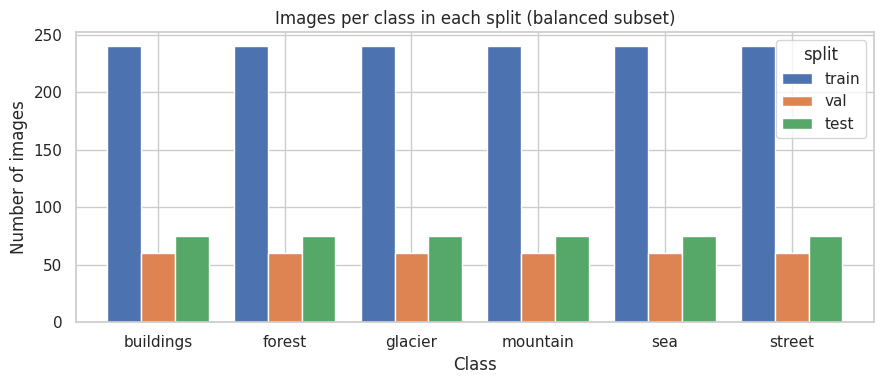

In [14]:
# Class distribution chart (train / val / test)
dist = selected.groupby(["label_name", "split"]).size().unstack()[["train", "val", "test"]]
display(dist)
ax = dist.plot(kind="bar", figsize=(9, 4), width=0.8)
ax.set_title("Images per class in each split (balanced subset)")
ax.set_xlabel("Class"); ax.set_ylabel("Number of images"); plt.xticks(rotation=0); plt.tight_layout()
save_fig(ax.figure, "01_class_distribution"); plt.show()

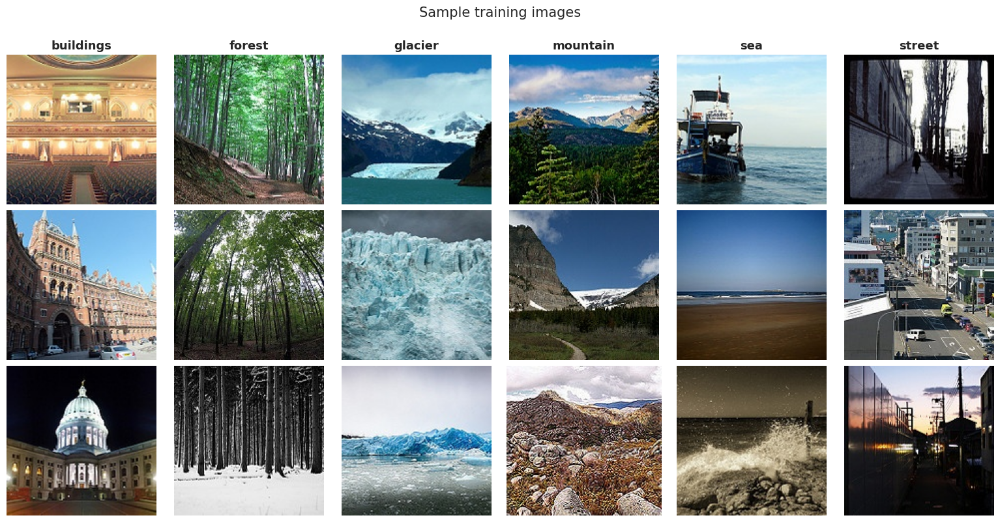

In [15]:
# Sample image grid (3 random training images per class)
fig, axes = plt.subplots(3, NUM_CLASSES, figsize=(2.6 * NUM_CLASSES, 8))
for j, c in enumerate(class_names):
    rows = train_df[train_df.label_name == c].sample(3, random_state=SEED)
    for i, (_, r) in enumerate(rows.iterrows()):
        axes[i, j].imshow(plt.imread(r.path)); axes[i, j].axis("off")
        if i == 0: axes[i, j].set_title(c, fontsize=13, fontweight="bold")
fig.suptitle("Sample training images", fontsize=15, y=1.0); plt.tight_layout()
save_fig(fig, "02_sample_images"); plt.show()

### 1.4 Prepare images

Images are resized to `128 × 128`. Augmentation (random flip + small rotation) is used only for training images. The same images and labels are used for both models, so the comparison is fair.

In [16]:
# Read an image, resize it, and keep pixel values from 0 to 255.
def decode_resize(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image = tf.image.resize(image, IMG_SIZE)
    return tf.cast(image, tf.float32), label

# Small, simple augmentation for training images only.
augmenter = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
])

In [17]:
def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (frame.path.values, frame.label.values.astype("int32"))
    )
    ds = ds.map(decode_resize, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.shuffle(len(frame), seed=SEED)
    ds = ds.batch(BATCH_SIZE)

    if training:
        ds = ds.map(
            lambda x, y: (augmenter(x, training=True), y),
            num_parallel_calls=AUTOTUNE
        )
    return ds.prefetch(AUTOTUNE)

In [18]:
train_ds = make_dataset(train_df, training=True)
val_ds   = make_dataset(val_df)
test_ds  = make_dataset(test_df)

# Keep the test images in an array for evaluation and Grad-CAM.
X_test = np.concatenate([x.numpy() for x, _ in test_ds])
y_test = np.concatenate([y.numpy() for _, y in test_ds])

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))
print("Image shape:", X_test[0].shape)

Training images: 1440
Validation images: 360
Test images: 450
Image shape: (128, 128, 3)


---
# Part 2 — Custom CNN

A CNN learns image features from the training images. We build a small network with three convolution + pooling blocks and a final six-class output layer.

In [19]:
def build_cnn():
    model = keras.Sequential([
        keras.Input(shape=(*IMG_SIZE, 3)),
        layers.Rescaling(1.0 / 255),

        layers.Conv2D(32, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),

        layers.Conv2D(64, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),

        layers.Conv2D(128, 3, activation="relu", padding="same",
                      name="last_conv_relu"),
        layers.MaxPooling2D(),

        layers.GlobalAveragePooling2D(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation="softmax")
    ])
    return model

In [20]:
cnn = build_cnn()
cnn.compile(
    optimizer=keras.optimizers.Adam(CNN_LR),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv_relu (Conv2D)         │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,894 (398.02 KB)

 Trainable params: 101,894 (398.02 KB)

 Non-trainable params: 0 (0.00 B)

### 2.1 Train the CNN

`EarlyStopping` stops training if validation loss stops improving and restores the best weights. We also measure the training time for the comparison later.

In [21]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=CNN_PATIENCE, restore_best_weights=True
    )
]

t0 = time.time()
cnn_history = cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=CNN_EPOCHS,
    callbacks=callbacks
)
cnn_time = time.time() - t0
print(f"\nCustom CNN: {len(cnn_history.history['loss'])} epochs in {cnn_time:.0f} s")

Epoch 1/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 14s 107ms/step - accuracy: 0.2479 - loss: 1.6985 - val_accuracy: 0.3667 - val_loss: 1.4568
Epoch 2/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 12s 66ms/step - accuracy: 0.3743 - loss: 1.4356 - val_accuracy: 0.4556 - val_loss: 1.3244
Epoch 3/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - accuracy: 0.4097 - loss: 1.3402 - val_accuracy: 0.4611 - val_loss: 1.2328
Epoch 4/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.4583 - loss: 1.2821 - val_accuracy: 0.4917 - val_loss: 1.2158
Epoch 5/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 65ms/step - accuracy: 0.4743 - loss: 1.2423 - val_accuracy: 0.4972 - val_loss: 1.1807
Epoch 6/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 62ms/step - accuracy: 0.4847 - loss: 1.1957 - val_accuracy: 0.5083 - val_loss: 1.1839
Epoch 7/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 62ms/step - accuracy: 0.5160 - loss: 1.1569 - val_accuracy: 0.5639 - val_loss: 1.1468
Epoch 8/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step - accuracy: 0.5500 - loss: 1.1143 - val_accuracy: 0.6028 

### 2.2 Helper functions: plots and evaluation

These three cells only define functions (no output). They are reused for both models.

In [22]:
def plot_training(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].plot(history.history["accuracy"], label="Train")
    axes[0].plot(history.history["val_accuracy"], label="Validation")
    axes[0].set_title("Accuracy")
    axes[1].plot(history.history["loss"], label="Train")
    axes[1].plot(history.history["val_loss"], label="Validation")
    axes[1].set_title("Loss")
    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    save_fig(fig, title.lower().replace(" ", "_"))
    plt.show()

In [23]:
def plot_confusion_matrix(y_true, y_pred, name):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_title(f"{name} — Confusion Matrix")
    plt.tight_layout()
    save_fig(fig, name.lower().replace(" ", "_") + "_confusion_matrix")
    plt.show()

def evaluate_model(model, name):
    probabilities = model.predict(X_test, verbose=0)
    predictions = np.argmax(probabilities, axis=1)
    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

    print(f"{name} — Test accuracy: {accuracy:.3f} | Test loss: {loss:.3f}")
    print(classification_report(y_test, predictions, target_names=class_names, zero_division=0))
    plot_confusion_matrix(y_test, predictions, name)

    return {
        "name": name, "accuracy": accuracy, "loss": loss,
        "predictions": predictions, "probabilities": probabilities,
        "macro_f1": precision_recall_fscore_support(
            y_test, predictions, average="macro", zero_division=0)[2],
    }

In [24]:
def show_predictions(result):
    fig, axes = plt.subplots(2, 3, figsize=(10, 7))
    for ax, i in zip(axes.flat, range(6)):
        ax.imshow(X_test[i].astype("uint8"))
        true_name = class_names[y_test[i]]
        pred_name = class_names[result["predictions"][i]]
        confidence = result["probabilities"][i].max()
        ax.set_title(f"True: {true_name}\nPred: {pred_name} ({confidence:.0%})")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

### 2.3 Training curves and test results

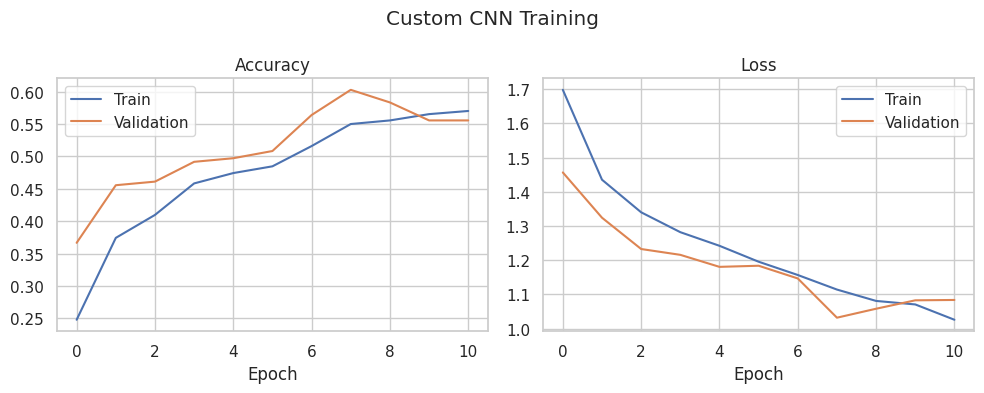

In [25]:
plot_training(cnn_history, "Custom CNN Training")

Custom CNN — Test accuracy: 0.569 | Test loss: 1.085
              precision    recall  f1-score   support

   buildings       0.40      0.59      0.47        75
      forest       0.80      0.87      0.83        75
     glacier       0.52      0.65      0.58        75
    mountain       0.65      0.52      0.58        75
         sea       0.57      0.43      0.49        75
      street       0.56      0.36      0.44        75

    accuracy                           0.57       450
   macro avg       0.58      0.57      0.57       450
weighted avg       0.58      0.57      0.57       450



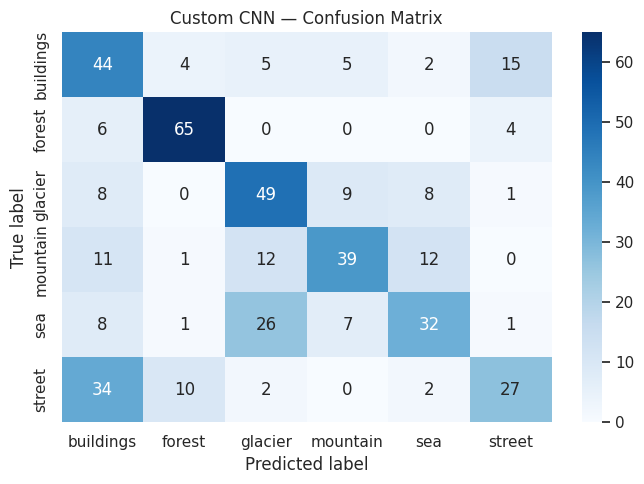

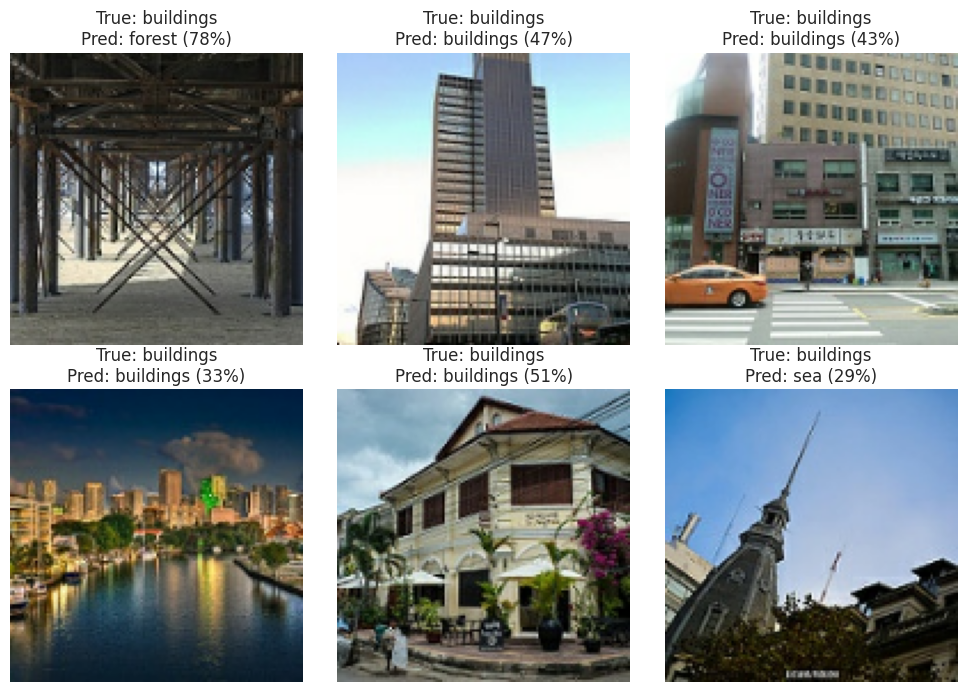

In [26]:
cnn_results = evaluate_model(cnn, "Custom CNN")
show_predictions(cnn_results)

---
# Part 3 — Transfer Learning with MobileNetV2

MobileNetV2 was pretrained on ImageNet. We freeze its learned image features and train a small new output layer for our six scene classes. This is the simpler Transfer Learning setup; fine-tuning is optional and is not needed to demonstrate Transfer Learning.

In [27]:
base_model = keras.applications.MobileNetV2(
    input_shape=(*IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False  # keep pretrained feature layers fixed

inputs = keras.Input(shape=(*IMG_SIZE, 3))
x = layers.Rescaling(1.0 / 127.5, offset=-1.0)(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

transfer_model = keras.Model(inputs, outputs)
transfer_model.compile(
    optimizer=keras.optimizers.Adam(HEAD_LR),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
transfer_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 3.1 Train the new classifier head

In [28]:
transfer_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=HEAD_PATIENCE, restore_best_weights=True
    )
]

t0 = time.time()
transfer_history = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=HEAD_EPOCHS,
    callbacks=transfer_callbacks
)
transfer_time = time.time() - t0
print(f"\nMobileNetV2: {len(transfer_history.history['loss'])} epochs in {transfer_time:.0f} s")

Epoch 1/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 21s 217ms/step - accuracy: 0.5917 - loss: 1.0811 - val_accuracy: 0.8167 - val_loss: 0.4697
Epoch 2/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 62ms/step - accuracy: 0.8361 - loss: 0.4771 - val_accuracy: 0.8389 - val_loss: 0.3910
Epoch 3/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - accuracy: 0.8500 - loss: 0.3845 - val_accuracy: 0.8500 - val_loss: 0.3538
Epoch 4/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 67ms/step - accuracy: 0.8757 - loss: 0.3405 - val_accuracy: 0.8639 - val_loss: 0.3450
Epoch 5/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - accuracy: 0.8993 - loss: 0.2927 - val_accuracy: 0.8583 - val_loss: 0.3428
Epoch 6/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.8972 - loss: 0.2831 - val_accuracy: 0.8472 - val_loss: 0.3684
Epoch 7/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 66ms/step - accuracy: 0.9104 - loss: 0.2511 - val_accuracy: 0.8722 - val_loss: 0.3389
Epoch 8/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.9194 - loss: 0.2286 - val_accuracy: 0.8639 -

### 3.2 Training curves and test results

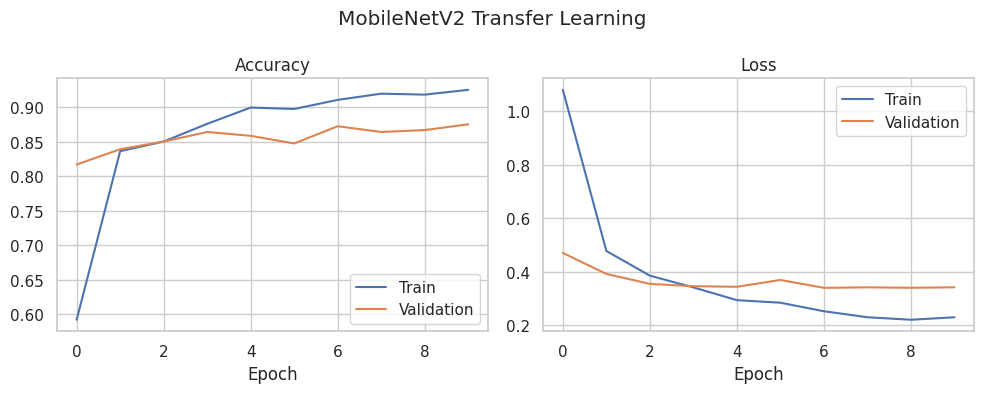

In [29]:
plot_training(transfer_history, "MobileNetV2 Transfer Learning")

MobileNetV2 — Test accuracy: 0.918 | Test loss: 0.233
              precision    recall  f1-score   support

   buildings       0.89      0.96      0.92        75
      forest       1.00      0.99      0.99        75
     glacier       0.80      0.91      0.85        75
    mountain       0.92      0.77      0.84        75
         sea       0.96      1.00      0.98        75
      street       0.96      0.88      0.92        75

    accuracy                           0.92       450
   macro avg       0.92      0.92      0.92       450
weighted avg       0.92      0.92      0.92       450



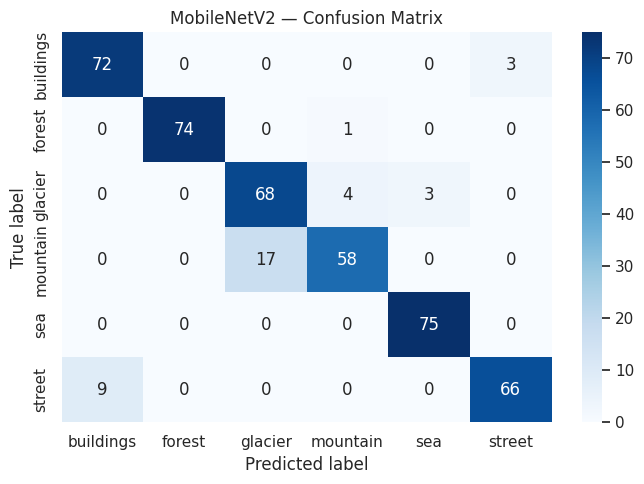

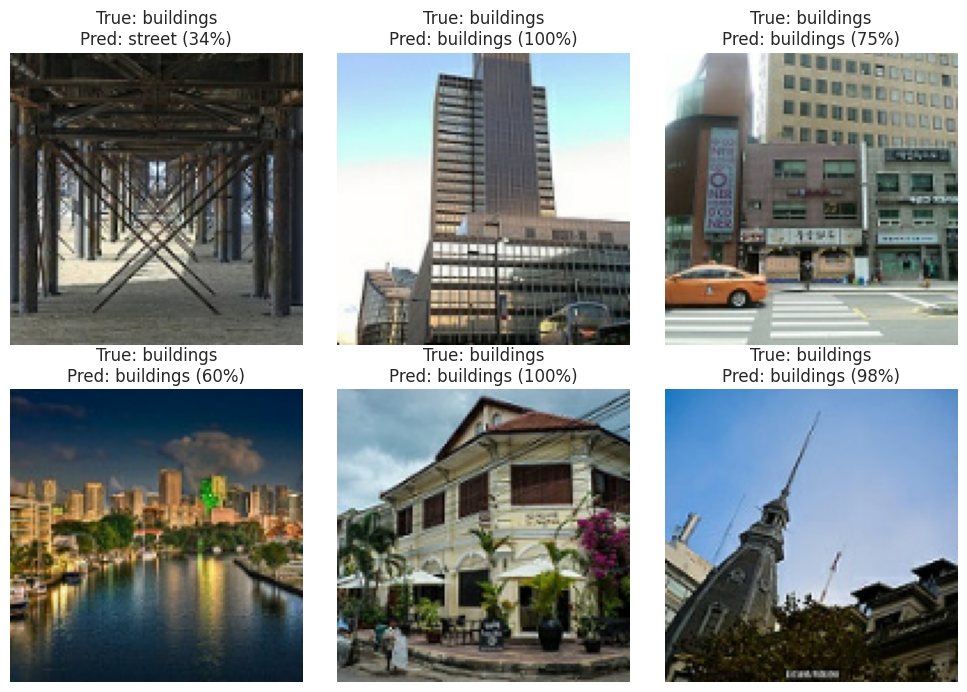

In [30]:
transfer_results = evaluate_model(transfer_model, "MobileNetV2")
show_predictions(transfer_results)

---
# Part 4 — Which model is better?

Accuracy is the share of correct predictions. Macro F1 averages the F1-score over the classes, so every class counts equally. All numbers below come from the **test set**, which was never used for training or early stopping.

### 4.1 Summary table

In [31]:
def summarize(name, model, history, results, seconds):
    h = pd.DataFrame(history.history)
    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    return {
        "Model": name,
        "Test accuracy": results["accuracy"],
        "Macro F1": results["macro_f1"],
        "Test loss": results["loss"],
        "Best val accuracy": h.val_accuracy.max(),
        "Epochs run": len(h),
        "Best epoch": int(h.val_loss.idxmin()) + 1,
        "Total params": model.count_params(),
        "Trainable params": trainable,
        "Training time (s)": seconds,
    }

comparison = pd.DataFrame([
    summarize("Custom CNN", cnn, cnn_history, cnn_results, cnn_time),
    summarize("MobileNetV2", transfer_model, transfer_history, transfer_results, transfer_time),
]).set_index("Model")

display(comparison.round(3).T)

Model,Custom CNN,MobileNetV2
Test accuracy,0.569,0.918
Macro F1,0.565,0.917
Test loss,1.085,0.233
Best val accuracy,0.603,0.875
Epochs run,11.000,10.000
Best epoch,8.000,7.000
Total params,101894.000,2265670.000
Trainable params,101894.000,7686.000
Training time (s),65.074,61.277


### 4.2 Accuracy, Macro F1 and test loss

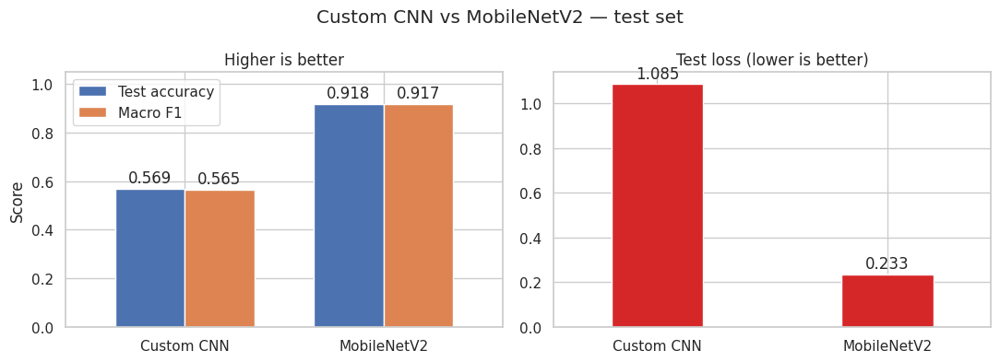

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

comparison[["Test accuracy", "Macro F1"]].plot(kind="bar", ax=axes[0], ylim=(0, 1.05), width=0.7)
axes[0].set_title("Higher is better"); axes[0].set_ylabel("Score")

comparison[["Test loss"]].plot(kind="bar", ax=axes[1], color="tab:red", width=0.4, legend=False)
axes[1].set_title("Test loss (lower is better)")

for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", padding=2)

fig.suptitle("Custom CNN vs MobileNetV2 — test set")
plt.tight_layout()
save_fig(fig, "model_comparison"); plt.show()

### 4.3 Per-class F1-score
Shows which scene classes each model finds easy or hard.

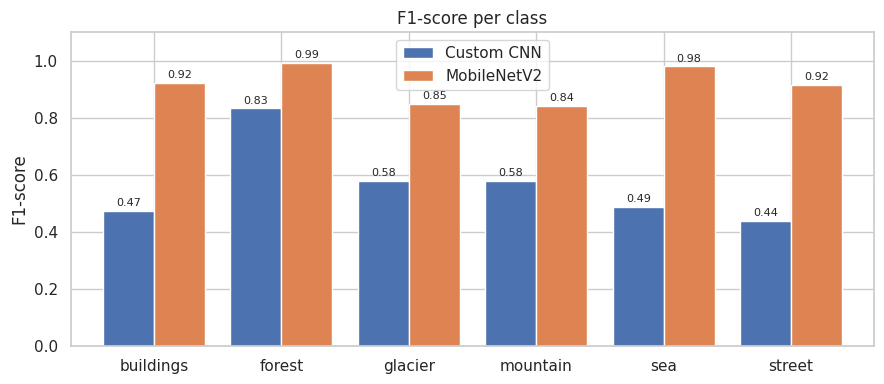

In [33]:
per_class_f1 = pd.DataFrame({
    r["name"]: precision_recall_fscore_support(
        y_test, r["predictions"], average=None, zero_division=0)[2]
    for r in (cnn_results, transfer_results)
}, index=class_names)

ax = per_class_f1.plot(kind="bar", figsize=(9, 4), ylim=(0, 1.1), width=0.8)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)
ax.set_title("F1-score per class"); ax.set_ylabel("F1-score"); ax.set_xlabel("")
plt.xticks(rotation=0); plt.tight_layout()
save_fig(ax.figure, "per_class_f1"); plt.show()

### 4.4 Confusion matrices side by side
Values are row-normalised: each row shows what fraction of a true class was predicted as each class (the diagonal is the per-class recall).

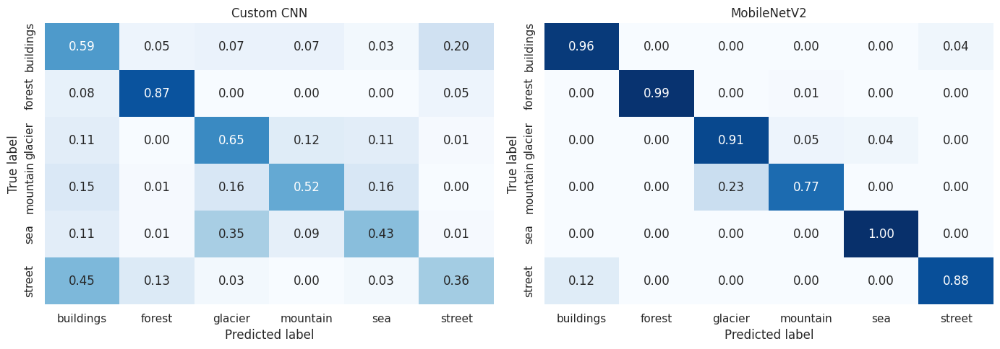

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, r in zip(axes, (cnn_results, transfer_results)):
    cm = confusion_matrix(y_test, r["predictions"], normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(r["name"]); ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
plt.tight_layout()
save_fig(fig, "confusion_matrices_side_by_side"); plt.show()

### 4.5 Do the two models make the same mistakes?

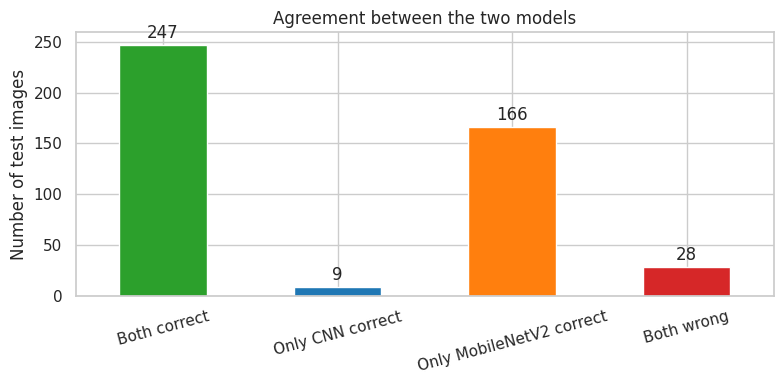

In [35]:
cnn_ok = cnn_results["predictions"] == y_test
tl_ok  = transfer_results["predictions"] == y_test

agreement = pd.Series({
    "Both correct":      int((cnn_ok & tl_ok).sum()),
    "Only CNN correct":  int((cnn_ok & ~tl_ok).sum()),
    "Only MobileNetV2 correct": int((~cnn_ok & tl_ok).sum()),
    "Both wrong":        int((~cnn_ok & ~tl_ok).sum()),
})

fig, ax = plt.subplots(figsize=(8, 4))
agreement.plot(kind="bar", ax=ax, color=["tab:green", "tab:blue", "tab:orange", "tab:red"])
ax.bar_label(ax.containers[0], padding=2)
ax.set_ylabel("Number of test images"); ax.set_title("Agreement between the two models")
plt.xticks(rotation=15); plt.tight_layout()
save_fig(fig, "model_agreement"); plt.show()

### 4.6 Verdict (generated from the numbers above)

In [36]:
def winner(col, higher=True):
    s = comparison[col]
    best = s.max() if higher else s.min()
    return " = ".join(s[s == best].index)

print("Best test accuracy :", winner("Test accuracy"),
      f"(CNN {comparison.loc['Custom CNN', 'Test accuracy']:.1%} vs "
      f"MobileNetV2 {comparison.loc['MobileNetV2', 'Test accuracy']:.1%})")
print("Best macro F1      :", winner("Macro F1"))
print("Lowest test loss   :", winner("Test loss", higher=False))
print("Fastest training   :", winner("Training time (s)", higher=False))
print("Fewest trainable parameters:", winner("Trainable params", higher=False))

overall = {winner("Test accuracy"), winner("Macro F1"), winner("Test loss", higher=False)}
if len(overall) == 1 and " = " not in next(iter(overall)):
    print(f"\n=> Overall best model on the test set: {next(iter(overall))}")
else:
    print("\n=> No single model wins every metric; compare the trade-offs in the table above.")

Best test accuracy : MobileNetV2 (CNN 56.9% vs MobileNetV2 91.8%)
Best macro F1      : MobileNetV2
Lowest test loss   : MobileNetV2
Fastest training   : MobileNetV2
Fewest trainable parameters: MobileNetV2

=> Overall best model on the test set: MobileNetV2


---
# Part 5 — Effect of the number of epochs

**Question:** as the epochs increase, does the error (loss) go down and the accuracy go up?

In general: both models improve quickly in the first epochs. Later the **training** loss can keep falling while the **validation** loss flattens or starts rising — that is **overfitting**, and it is exactly what `EarlyStopping` protects us from. The ★ marks the epoch with the lowest validation loss (the weights we keep).

### 5.1 Both models on the same curves

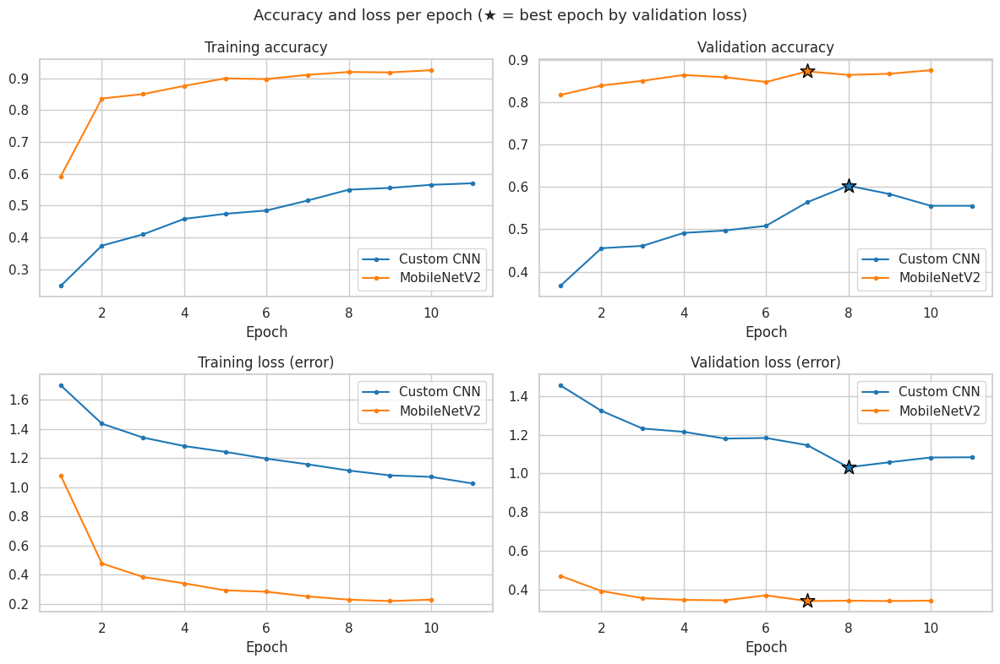

In [37]:
from matplotlib.ticker import MaxNLocator

histories = {
    "Custom CNN": pd.DataFrame(cnn_history.history),
    "MobileNetV2": pd.DataFrame(transfer_history.history),
}
for h in histories.values():
    h.index = np.arange(1, len(h) + 1)          # epochs numbered from 1
    h.index.name = "epoch"
colors = {"Custom CNN": "tab:blue", "MobileNetV2": "tab:orange"}

panels = [("accuracy", "Training accuracy"), ("val_accuracy", "Validation accuracy"),
          ("loss", "Training loss (error)"),  ("val_loss", "Validation loss (error)")]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (col, title) in zip(axes.flat, panels):
    for name, h in histories.items():
        ax.plot(h.index, h[col], marker="o", ms=3, label=name, color=colors[name])
        if col.startswith("val"):
            best = h.val_loss.idxmin()
            ax.scatter(best, h.loc[best, col], s=160, marker="*", color=colors[name],
                       edgecolor="black", zorder=5)
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.legend()
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
fig.suptitle("Accuracy and loss per epoch (★ = best epoch by validation loss)", fontsize=13)
plt.tight_layout()
save_fig(fig, "epoch_curves_both_models"); plt.show()

### 5.2 Overfitting check: train–validation gap

A growing gap means the model is memorising the training images. (Training accuracy is measured with dropout and augmentation switched on, so early in training it can even be *lower* than validation accuracy.)

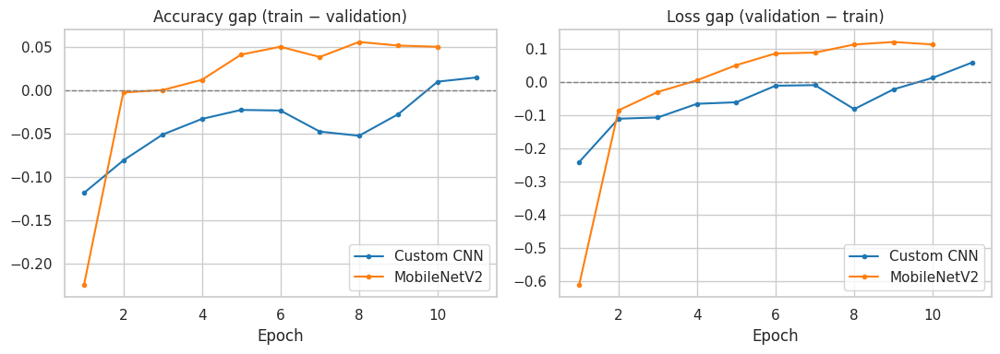

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, h in histories.items():
    axes[0].plot(h.index, h.accuracy - h.val_accuracy, marker="o", ms=3, label=name, color=colors[name])
    axes[1].plot(h.index, h.val_loss - h.loss, marker="o", ms=3, label=name, color=colors[name])
axes[0].set_title("Accuracy gap (train − validation)")
axes[1].set_title("Loss gap (validation − train)")
for ax in axes:
    ax.axhline(0, color="gray", lw=1, ls="--"); ax.set_xlabel("Epoch"); ax.legend()
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout()
save_fig(fig, "epoch_generalization_gap"); plt.show()

### 5.3 Metrics for every epoch

In [39]:
for name, h in histories.items():
    print(f"\n{name}")
    display(h.round(3))


Custom CNN


,accuracy,loss,val_accuracy,val_loss
epoch,,,,
1,0.248,1.698,0.367,1.457
2,0.374,1.436,0.456,1.324
3,0.410,1.340,0.461,1.233
4,0.458,1.282,0.492,1.216
5,0.474,1.242,0.497,1.181
6,0.485,1.196,0.508,1.184
7,0.516,1.157,0.564,1.147
8,0.550,1.114,0.603,1.032
9,0.556,1.081,0.583,1.058



MobileNetV2


,accuracy,loss,val_accuracy,val_loss
epoch,,,,
1,0.592,1.081,0.817,0.470
2,0.836,0.477,0.839,0.391
3,0.850,0.384,0.850,0.354
4,0.876,0.341,0.864,0.345
5,0.899,0.293,0.858,0.343
6,0.897,0.283,0.847,0.368
7,0.910,0.251,0.872,0.339
8,0.919,0.229,0.864,0.341
9,0.918,0.219,0.867,0.339


### 5.4 Trend summary
Spearman correlation with the epoch number: close to **−1** for loss means "loss keeps going down", close to **+1** for accuracy means "accuracy keeps going up".

In [40]:
from scipy.stats import spearmanr

rows = []
for name, h in histories.items():
    n = len(h)
    gap = h.accuracy - h.val_accuracy
    rows.append({
        "Model": name, "Epochs run": n, "Best epoch": int(h.val_loss.idxmin()),
        "Val loss first": h.val_loss.iloc[0],     "Val loss best": h.val_loss.min(),
        "Val acc first": h.val_accuracy.iloc[0],  "Val acc best": h.val_accuracy.max(),
        "Corr(epoch, val loss)": spearmanr(h.index, h.val_loss)[0] if n > 2 else np.nan,
        "Corr(epoch, val acc)":  spearmanr(h.index, h.val_accuracy)[0] if n > 2 else np.nan,
        "Gap first": gap.iloc[0], "Gap last": gap.iloc[-1],
    })
trend = pd.DataFrame(rows).set_index("Model")
display(trend.round(3).T)

Model,Custom CNN,MobileNetV2
Epochs run,11.000,10.000
Best epoch,8.000,7.000
Val loss first,1.457,0.470
Val loss best,1.032,0.339
Val acc first,0.367,0.817
Val acc best,0.603,0.875
"Corr(epoch, val loss)",-0.900,-0.818
"Corr(epoch, val acc)",0.852,0.857
Gap first,-0.119,-0.225
Gap last,0.015,0.050


In [41]:
for name, r in trend.iterrows():
    best, n = int(r["Best epoch"]), int(r["Epochs run"])
    print(f"{name}")
    print(f"  - Validation loss: {r['Val loss first']:.3f} (epoch 1) -> {r['Val loss best']:.3f} (best, epoch {best}).")
    print(f"  - Validation accuracy: {r['Val acc first']:.1%} (epoch 1) -> {r['Val acc best']:.1%} (best).")
    if best == n:
        print("  - Still improving at the last epoch -> more epochs could help.")
    else:
        print(f"  - No improvement after epoch {best} -> extra epochs did not help (early stopping / overfitting risk).")
    growth = r["Gap last"] - r["Gap first"]
    if growth > 0.05:
        print(f"  - The train-validation accuracy gap grew by {growth:.1%} -> sign of overfitting.")
    else:
        print("  - The train-validation gap stayed small -> no strong overfitting.")
    print()

Custom CNN
  - Validation loss: 1.457 (epoch 1) -> 1.032 (best, epoch 8).
  - Validation accuracy: 36.7% (epoch 1) -> 60.3% (best).
  - No improvement after epoch 8 -> extra epochs did not help (early stopping / overfitting risk).
  - The train-validation accuracy gap grew by 13.3% -> sign of overfitting.

MobileNetV2
  - Validation loss: 0.470 (epoch 1) -> 0.339 (best, epoch 7).
  - Validation accuracy: 81.7% (epoch 1) -> 87.5% (best).
  - No improvement after epoch 7 -> extra epochs did not help (early stopping / overfitting risk).
  - The train-validation accuracy gap grew by 27.5% -> sign of overfitting.



---
# Part 6 — XAI with Grad-CAM (both models)

Grad-CAM creates a heatmap highlighting the image regions that influenced the model's predicted class. Warm colors (red/yellow) mean stronger influence. It is an approximate explanation, not proof that the highlighted region caused the prediction.

We apply it to the **Custom CNN** and to the **MobileNetV2 Transfer Learning model**, and then compare both on the same images.

Note: the last convolutional feature map is small (32×32 for our CNN, 4×4 for MobileNetV2 at 128 px), so the MobileNetV2 heatmaps look coarser after being resized to the image.

### 6.1 Grad-CAM implementation

In [42]:
def find_last_conv_layer(model, preferred=None):
    if preferred:
        try:
            lyr = model.get_layer(preferred)
            if len(lyr.output.shape) == 4:
                return lyr
        except Exception:
            print(f"Warning: layer '{preferred}' not usable in {model.name}, falling back to automatic detection.")
    skip = (layers.MaxPooling2D, layers.Dropout, layers.SpatialDropout2D, layers.GlobalAveragePooling2D,
            layers.GlobalMaxPooling2D, layers.Flatten, layers.Dense)
    for lyr in reversed(model.layers):
        if isinstance(lyr, skip):
            continue
        try:
            if len(lyr.output.shape) == 4:
                return lyr
        except Exception:
            continue
    raise ValueError(f"No convolutional (4-D) layer found in {model.name}")

In [43]:
def run_layers(layer_list, x):
    for lyr in layer_list:
        x = lyr(x)
    return x

class GradCAM:
    def __init__(self, model, preferred_layer=None):
        self.model = model
        self.layer = find_last_conv_layer(model, preferred_layer)
        idx = model.layers.index(self.layer)
        # Split the model into "layers up to the conv feature map" and "head layers".
        self.pre_layers = [l for l in model.layers[:idx + 1] if not isinstance(l, layers.InputLayer)]
        self.head_layers = list(model.layers[idx + 1:])
        print(f"[{model.name}] Grad-CAM layer: '{self.layer.name}' | feature map: {tuple(self.layer.output.shape[1:])}")

    def heatmap(self, img, class_idx=None):
        x = tf.convert_to_tensor(img[None], dtype=tf.float32)
        with tf.GradientTape() as tape:
            fmap = run_layers(self.pre_layers, x)
            tape.watch(fmap)
            preds = run_layers(self.head_layers, fmap)
            if class_idx is None:
                class_idx = int(tf.argmax(preds[0]))          # explain the PREDICTED class
            score = preds[:, class_idx]
        grads = tape.gradient(score, fmap)                    # d(score)/d(feature maps)
        weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
        cam = tf.nn.relu(tf.reduce_sum(weights * fmap, axis=-1))[0]
        cam = cam / (tf.reduce_max(cam) + 1e-8)               # normalise to [0, 1]
        return cam.numpy(), preds[0].numpy(), class_idx

In [44]:
def check_gradcam(gc, X, n=8):
    # Our split forward pass must equal the real model output.
    x = tf.convert_to_tensor(X[:n], tf.float32)
    split_out = run_layers(gc.head_layers, run_layers(gc.pre_layers, x)).numpy()
    real_out = gc.model.predict(X[:n], verbose=0)
    assert np.allclose(split_out, real_out, atol=1e-4), f"Grad-CAM does not reproduce {gc.model.name} output"
    print(f"OK: {gc.model.name} reproduced (max diff {np.abs(split_out - real_out).max():.2e})")

cam_cnn = GradCAM(cnn, preferred_layer="last_conv_relu")
cam_transfer = GradCAM(transfer_model)
check_gradcam(cam_cnn, X_test)
check_gradcam(cam_transfer, X_test)

[sequential_1] Grad-CAM layer: 'last_conv_relu' | feature map: (32, 32, 128)
[functional_2] Grad-CAM layer: 'mobilenetv2_1.00_128' | feature map: (4, 4, 1280)
OK: sequential_1 reproduced (max diff 2.09e-07)
OK: functional_2 reproduced (max diff 1.40e-06)


### 6.2 Plotting helpers

In [45]:
def overlay(img_u8, cam, alpha=0.4):
    cam_up = tf.image.resize(cam[..., None], img_u8.shape[:2], method="bilinear").numpy()[..., 0]
    heat = plt.get_cmap("jet")(cam_up)[..., :3]
    return np.clip((1 - alpha) * (img_u8 / 255.0) + alpha * heat, 0, 1), cam_up

def pick_examples(y_pred, n_correct=3, n_wrong=3):
    rng = np.random.default_rng(SEED)
    ok, bad = np.where(y_pred == y_test)[0], np.where(y_pred != y_test)[0]
    chosen = list(rng.choice(ok, min(n_correct, len(ok)), replace=False)) \
           + list(rng.choice(bad, min(n_wrong, len(bad)), replace=False))
    if len(bad) == 0:
        print("No misclassified test images for this model - showing correct examples only.")
    return chosen

In [46]:
def gradcam_figure(gc, res, fname):
    idxs = pick_examples(res["predictions"])
    fig, axes = plt.subplots(len(idxs), 3, figsize=(10, 3.4 * len(idxs)))
    axes = np.atleast_2d(axes)
    for r, i in enumerate(idxs):
        img = X_test[i]; cam, probs, pred = gc.heatmap(img)
        assert pred == res["predictions"][i], "Grad-CAM class differs from model.predict"
        ov, cam_up = overlay(img, cam)
        axes[r, 0].imshow(img.astype("uint8")); axes[r, 0].set_title(f"True: {class_names[y_test[i]]}")
        axes[r, 1].imshow(cam_up, cmap="jet", vmin=0, vmax=1); axes[r, 1].set_title("Grad-CAM heatmap")
        axes[r, 2].imshow(ov); axes[r, 2].set_title(f"Pred: {class_names[pred]} ({probs[pred]:.1%})",
                                                   color="green" if pred == y_test[i] else "red")
        for a in axes[r]: a.axis("off")
    fig.suptitle(f"Grad-CAM — {res['name']} (first rows correct, last rows misclassified)", fontsize=13, y=1.0)
    plt.tight_layout(); save_fig(fig, fname); plt.show()

### 6.3 Grad-CAM — Custom CNN

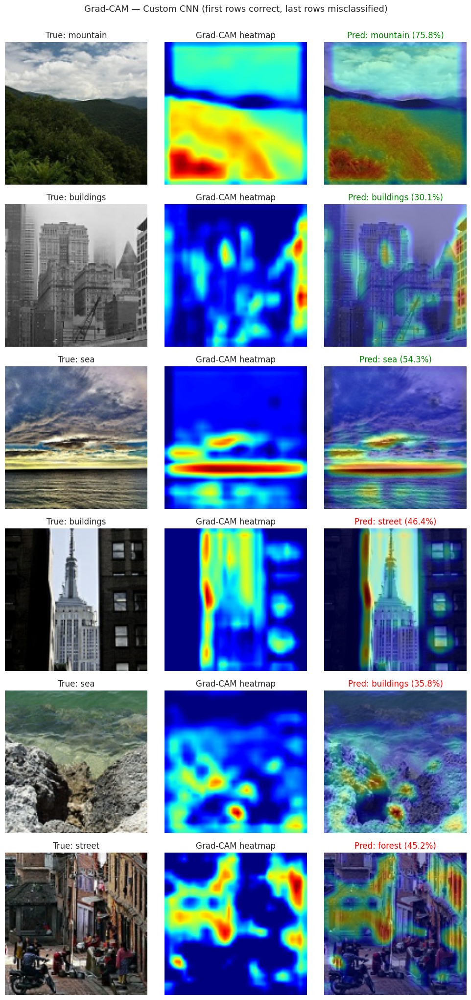

In [47]:
gradcam_figure(cam_cnn, cnn_results, "gradcam_cnn")

### 6.4 Grad-CAM — MobileNetV2 (Transfer Learning)

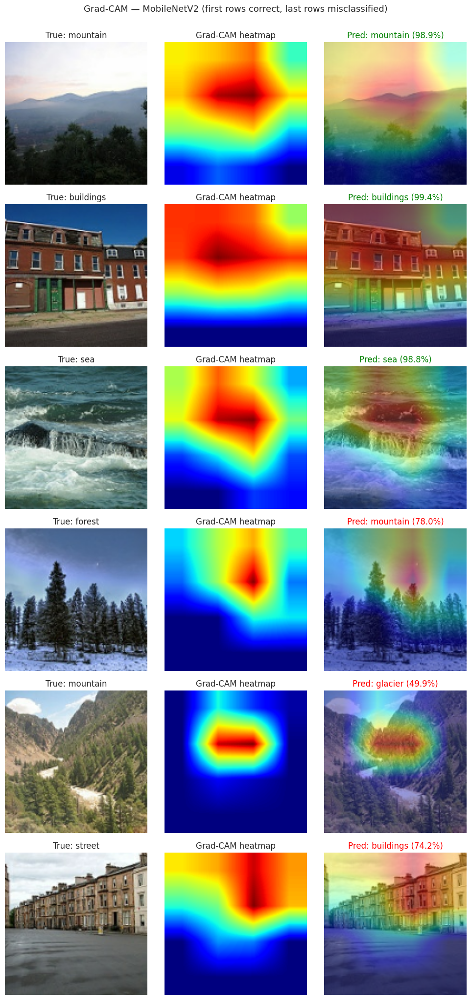

In [48]:
gradcam_figure(cam_transfer, transfer_results, "gradcam_mobilenetv2")

### 6.5 Side-by-side comparison on the same images

Same test image, two models: where does each one look? Green title = correct prediction, red = wrong.

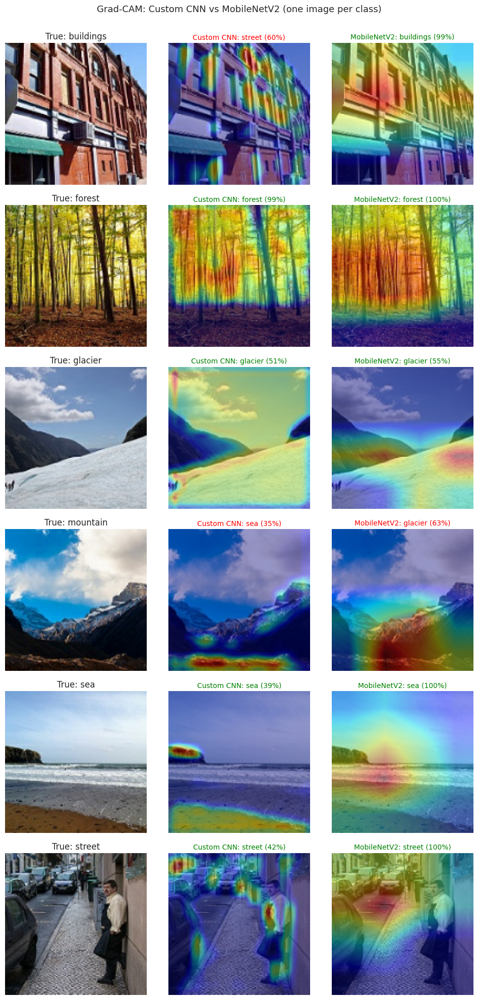

In [49]:
def compare_gradcam(idxs, title, fname):
    fig, axes = plt.subplots(len(idxs), 3, figsize=(10, 3.3 * len(idxs)))
    axes = np.atleast_2d(axes)
    for r, i in enumerate(idxs):
        img = X_test[i]
        axes[r, 0].imshow(img.astype("uint8")); axes[r, 0].set_title(f"True: {class_names[y_test[i]]}")
        for c, (name, gc) in enumerate([("Custom CNN", cam_cnn), ("MobileNetV2", cam_transfer)], start=1):
            cam, probs, pred = gc.heatmap(img)
            axes[r, c].imshow(overlay(img, cam)[0])
            axes[r, c].set_title(f"{name}: {class_names[pred]} ({probs[pred]:.0%})",
                                 color="green" if pred == y_test[i] else "red", fontsize=10)
        for a in axes[r]: a.axis("off")
    fig.suptitle(title, fontsize=13, y=1.0)
    plt.tight_layout(); save_fig(fig, fname); plt.show()

rng = np.random.default_rng(SEED)
one_per_class = [int(rng.choice(np.where(y_test == c)[0])) for c in range(NUM_CLASSES)]
compare_gradcam(one_per_class, "Grad-CAM: Custom CNN vs MobileNetV2 (one image per class)", "gradcam_comparison")

### 6.6 Images where the two models disagree

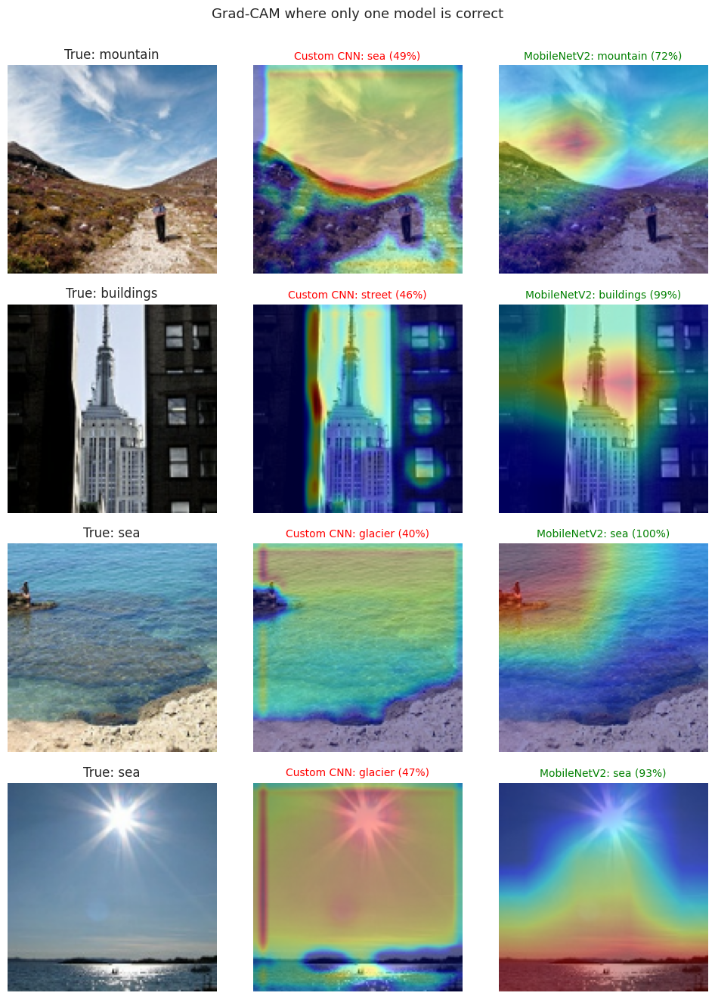

In [50]:
disagree = np.where(cnn_ok != tl_ok)[0]
if len(disagree) == 0:
    print("The two models are correct/wrong on exactly the same test images - nothing to show.")
else:
    chosen = [int(i) for i in np.random.default_rng(SEED).choice(disagree, min(4, len(disagree)), replace=False)]
    compare_gradcam(chosen, "Grad-CAM where only one model is correct", "gradcam_disagreement")

## Final checklist

- [ ] Custom CNN trained from scratch.
- [ ] MobileNetV2 Transfer Learning trained.
- [ ] Accuracy/loss curves displayed for both models.
- [ ] Classification reports and confusion matrices displayed.
- [ ] Model comparison: table, metric bars, per-class F1, confusion matrices, agreement, verdict.
- [ ] Epoch analysis: both models on the same curves, overfitting gap, per-epoch table, trend summary.
- [ ] Grad-CAM heatmaps displayed for **both** models + side-by-side comparison.

**Tip:** Run the notebook from top to bottom. If you get a Kaggle authentication error, use the dataset's Kaggle page to download `archive.zip`, upload it to Google Drive, then set `MANUAL_SOURCE` in the configuration cell to the ZIP path.